
# MoovUp — Sprint 4: Artificial Intelligence & Chatbot

## Objetivo
Treinar e avaliar dois modelos de Machine Learning usando a base de 500 usuários do MoovUp.

## Modelo 1 — Classificação
Prever o nível de engajamento dos usuários: baixo, médio ou alto.

## Modelo 2 — Regressão
Estimar os pontos acumulados pelos usuários.

## Base de dados
Arquivo: `base_moovup_500_usuarios.csv`

A base possui 500 registros e 11 colunas, sem valores vazios identificados na validação inicial.


In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("base_moovup_500_usuarios.csv")

display(df.head())

,id_usuario,idade,regiao,transporte_principal,frequencia_uso_semana,pontos_acumulados,pontos_resgatados,bilhetes_resgatados,acoes_realizadas,pontuacao_engajamento,nivel_engajamento
0,1,56,Norte,Trem,6,519,516,4,24,230.35,Alto
1,2,46,Centro,Trem,1,1373,466,1,17,123.39,Baixo
2,3,32,Leste,Metro,3,1240,929,1,13,126.69,Baixo
3,4,60,Leste,Metro,5,965,777,2,29,232.42,Alto
4,5,25,Centro,Onibus,6,677,344,4,6,140.21,Medio


In [ ]:
print("Quantidade de registros e colunas:", df.shape)

print("\nValores vazios:")
print(df.isnull().sum())

print("\nInformações das colunas:")
df.info()

Quantidade de registros e colunas: (500, 11)

Valores vazios:
id_usuario               0
idade                    0
regiao                   0
transporte_principal     0
frequencia_uso_semana    0
pontos_acumulados        0
pontos_resgatados        0
bilhetes_resgatados      0
acoes_realizadas         0
pontuacao_engajamento    0
nivel_engajamento        0
dtype: int64

Informações das colunas:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_usuario             500 non-null    int64  
 1   idade                  500 non-null    int64  
 2   regiao                 500 non-null    str    
 3   transporte_principal   500 non-null    str    
 4   frequencia_uso_semana  500 non-null    int64  
 5   pontos_acumulados      500 non-null    int64  
 6   pontos_resgatados      500 non-null    int64  
 7   bilhetes_resgatados    500 non-null

In [6]:
%pip install pandas numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
print("Distribuição dos níveis de engajamento:")

print(df["nivel_engajamento"].value_counts())

print("\nPercentual por categoria:")

print(df["nivel_engajamento"].value_counts(normalize=True) * 100)

Distribuição dos níveis de engajamento:
nivel_engajamento
Alto     167
Baixo    167
Medio    166
Name: count, dtype: int64

Percentual por categoria:
nivel_engajamento
Alto     33.4
Baixo    33.4
Medio    33.2
Name: proportion, dtype: float64


In [ ]:
X = df.drop(columns=[
    "id_usuario",
    "nivel_engajamento",
    "pontuacao_engajamento"
])

y = df["nivel_engajamento"]

X = pd.get_dummies(X, drop_first=True)

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dados preparados com sucesso!")
print("Dados para treinamento:", X_treino.shape)
print("Dados para teste:", X_teste.shape)

Dados preparados com sucesso!
Dados para treinamento: (400, 12)
Dados para teste: (100, 12)


In [9]:
modelo_classificacao = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

modelo_classificacao.fit(X_treino, y_treino)

previsoes = modelo_classificacao.predict(X_teste)

acuracia = accuracy_score(y_teste, previsoes)

print("Modelo de Classificação treinado!")
print("Acurácia:", round(acuracia * 100, 2), "%")

print("\nRelatório de classificação:")
print(classification_report(y_teste, previsoes))

Modelo de Classificação treinado!
Acurácia: 82.0 %

Relatório de classificação:
              precision    recall  f1-score   support

        Alto       0.89      0.91      0.90        34
       Baixo       0.81      0.88      0.84        33
       Medio       0.76      0.67      0.71        33

    accuracy                           0.82       100
   macro avg       0.82      0.82      0.82       100
weighted avg       0.82      0.82      0.82       100



In [10]:

X_reg = df.drop(columns=[
    "id_usuario",
    "pontos_acumulados",
    "pontuacao_engajamento",
    "nivel_engajamento"
])

y_reg = df["pontos_acumulados"]

X_reg = pd.get_dummies(X_reg, drop_first=True)

X_reg_treino, X_reg_teste, y_reg_treino, y_reg_teste = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Dados da regressão preparados!")
print("Dados para treinamento:", X_reg_treino.shape)
print("Dados para teste:", X_reg_teste.shape)

Dados da regressão preparados!
Dados para treinamento: (400, 11)
Dados para teste: (100, 11)


In [11]:
modelo_regressao = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

modelo_regressao.fit(X_reg_treino, y_reg_treino)

previsoes_reg = modelo_regressao.predict(X_reg_teste)

mae = mean_absolute_error(y_reg_teste, previsoes_reg)
rmse = np.sqrt(mean_squared_error(y_reg_teste, previsoes_reg))
r2 = r2_score(y_reg_teste, previsoes_reg)

print("Modelo de Regressão treinado!")
print("Erro médio absoluto (MAE):", round(mae, 2))
print("Raiz do erro quadrático médio (RMSE):", round(rmse, 2))
print("Coeficiente de determinação (R²):", round(r2, 4))

Modelo de Regressão treinado!
Erro médio absoluto (MAE): 365.1
Raiz do erro quadrático médio (RMSE): 432.44
Coeficiente de determinação (R²): -0.1799


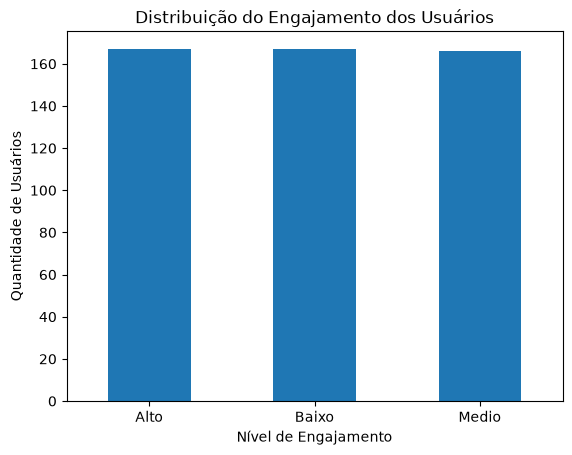

In [12]:
df["nivel_engajamento"].value_counts().plot(
    kind="bar",
    title="Distribuição do Engajamento dos Usuários"
)

plt.xlabel("Nível de Engajamento")
plt.ylabel("Quantidade de Usuários")
plt.xticks(rotation=0)
plt.show()

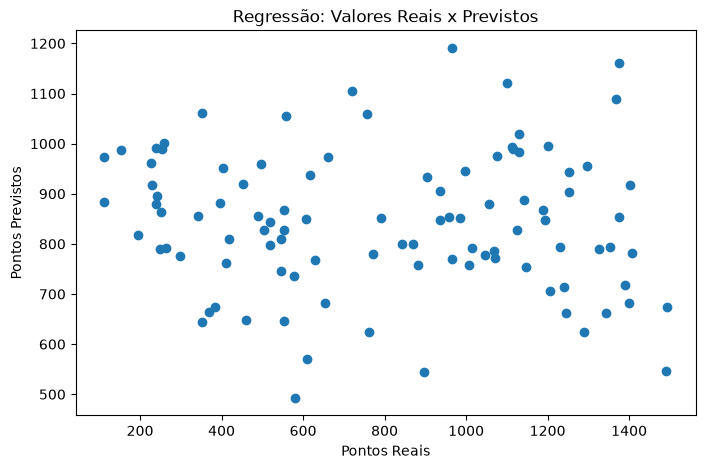

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(y_reg_teste, previsoes_reg)

plt.xlabel("Pontos Reais")
plt.ylabel("Pontos Previstos")
plt.title("Regressão: Valores Reais x Previstos")

plt.show()

In [ ]:
import joblib

joblib.dump(modelo_classificacao, "modelo_engajamento_notebook.joblib")
joblib.dump(modelo_regressao, "modelo_pontos_notebook.joblib")

print("Modelos salvos com sucesso!")

Modelos salvos com sucesso!


In [15]:
from sklearn.ensemble import ExtraTreesRegressor

modelo_extra = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42
)

modelo_extra.fit(X_reg_treino, y_reg_treino)

previsoes_extra = modelo_extra.predict(X_reg_teste)

mae_extra = mean_absolute_error(y_reg_teste, previsoes_extra)
rmse_extra = np.sqrt(mean_squared_error(y_reg_teste, previsoes_extra))
r2_extra = r2_score(y_reg_teste, previsoes_extra)

print("RESULTADO DO EXTRA TREES")
print("MAE:", round(mae_extra, 2))
print("RMSE:", round(rmse_extra, 2))
print("R²:", round(r2_extra, 4))

RESULTADO DO EXTRA TREES
MAE: 372.39
RMSE: 441.68
R²: -0.2309


In [16]:
correlacao = df.corr(numeric_only=True)

print("Correlação com pontos acumulados:")

print(
    correlacao["pontos_acumulados"]
    .sort_values(ascending=False)
)

print("\nEstatísticas dos pontos acumulados:")
print(df["pontos_acumulados"].describe())

Correlação com pontos acumulados:
pontos_acumulados        1.000000
pontuacao_engajamento    0.038493
idade                    0.033262
acoes_realizadas        -0.021543
frequencia_uso_semana   -0.024739
bilhetes_resgatados     -0.025585
pontos_resgatados       -0.065842
id_usuario              -0.073908
Name: pontos_acumulados, dtype: float64

Estatísticas dos pontos acumulados:
count     500.00000
mean      833.18400
std       399.86947
min       101.00000
25%       480.00000
50%       846.50000
75%      1188.50000
max      1499.00000
Name: pontos_acumulados, dtype: float64


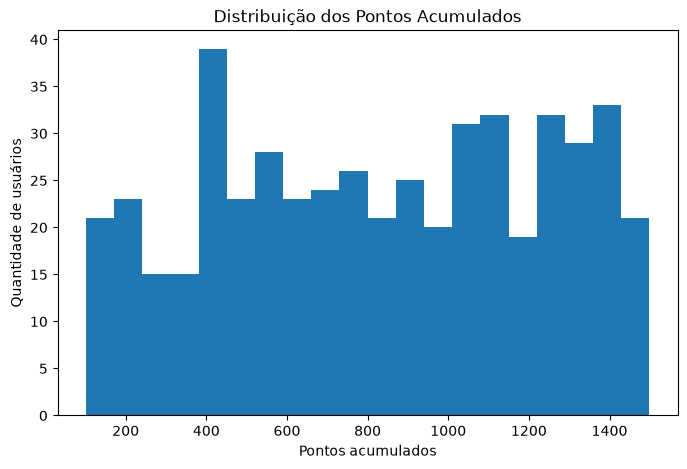

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(df["pontos_acumulados"], bins=20)

plt.title("Distribuição dos Pontos Acumulados")
plt.xlabel("Pontos acumulados")
plt.ylabel("Quantidade de usuários")

plt.show()

In [18]:
from sklearn.ensemble import GradientBoostingRegressor

modelo_gradient = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

modelo_gradient.fit(X_reg_treino, y_reg_treino)

previsoes_gradient = modelo_gradient.predict(X_reg_teste)

mae_gradient = mean_absolute_error(y_reg_teste, previsoes_gradient)
rmse_gradient = np.sqrt(mean_squared_error(y_reg_teste, previsoes_gradient))
r2_gradient = r2_score(y_reg_teste, previsoes_gradient)

print("RESULTADO GRADIENT BOOSTING")
print("MAE:", round(mae_gradient, 2))
print("RMSE:", round(rmse_gradient, 2))
print("R²:", round(r2_gradient, 4))

RESULTADO GRADIENT BOOSTING
MAE: 352.3
RMSE: 408.01
R²: -0.0504


In [19]:
modelo_gradient_2 = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.03,
    max_depth=3,
    random_state=42
)

modelo_gradient_2.fit(X_reg_treino, y_reg_treino)

previsoes_gradient_2 = modelo_gradient_2.predict(X_reg_teste)

print("MAE:", round(mean_absolute_error(y_reg_teste, previsoes_gradient_2), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_reg_teste, previsoes_gradient_2)), 2))
print("R²:", round(r2_score(y_reg_teste, previsoes_gradient_2), 4))

MAE: 348.39
RMSE: 407.49
R²: -0.0477


In [20]:
import pandas as pd

importancias = pd.Series(
    modelo_gradient_2.feature_importances_,
    index=X_reg.columns
)

print(importancias.sort_values(ascending=False))

pontos_resgatados              0.294446
idade                          0.214691
acoes_realizadas               0.171971
frequencia_uso_semana          0.116649
bilhetes_resgatados            0.054118
regiao_Sul                     0.043882
regiao_Oeste                   0.028887
transporte_principal_Trem      0.025302
regiao_Leste                   0.019795
transporte_principal_Onibus    0.017579
regiao_Norte                   0.012680
dtype: float64


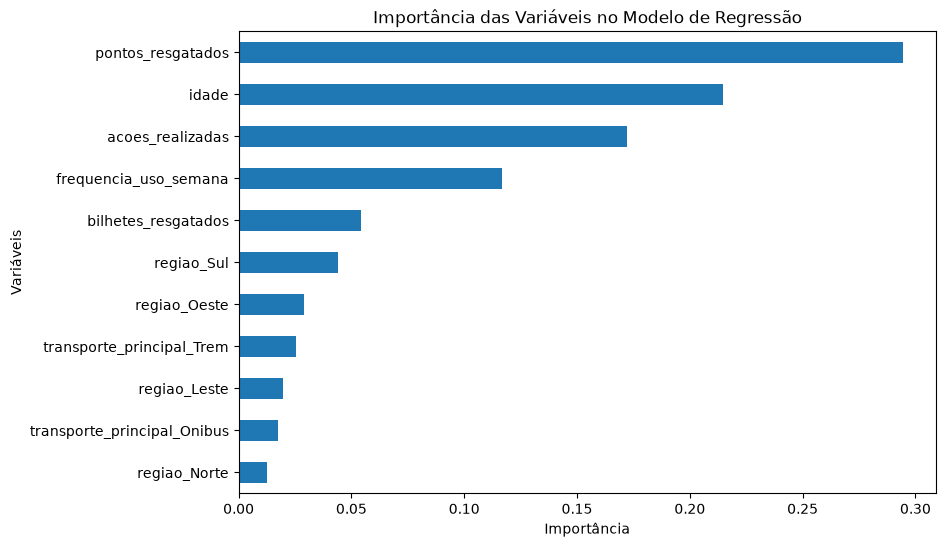

In [21]:
importancias.sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title="Importância das Variáveis no Modelo de Regressão"
)

plt.xlabel("Importância")
plt.ylabel("Variáveis")
plt.show()

In [22]:
import joblib

joblib.dump(
    modelo_gradient_2,
    "modelo_pontos_gradient_boosting.joblib"
)

print("Melhor modelo de regressão salvo com sucesso!")

Melhor modelo de regressão salvo com sucesso!
